# 01 — Multi-Study Harmonization & TabPFN v2 Forensic Metadata Audit (WP1)

**Objective:** Audit, deduplicate, and harmonize the core *Arabidopsis thaliana* hypobaric and exploration-atmosphere transcriptomic compendium (`GSE87867`, `GSE87868`/`OSD-136`, `GSE87903`, and `GSE87904`), resolve conflicting sample metadata in `GSE87903` using raw Affymetrix `.CEL` hybridization forensics and out-of-fold **TabPFN v2** probabilistic organ classification ([Hollmann et al., *Nature* 2025](https://www.nature.com/articles/s41586-024-08328-6)), and explain unbalanced replicate counts (`n=4`).

## 1. Loading & Deduplicating the 130 Unique Hypobaric Microarrays
Across `GSE87867` (20 GSMs), `GSE87868` (9 GSMs), `GSE87903` (47 GSMs), and `GSE87904` (72 GSMs), there are 148 total GEO records. However, 18 GSMs (`GSM2342073`–`GSM2342090`) are cross-listed identically in both `GSE87867` and `GSE87903`. We verify exact numerical identity (`max_abs_diff = 0.0`, `Pearson r = 1.000000`) and deduplicate to **130 unique biological arrays** across **22,746 biological ATH1 probesets**.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import Image, display

PROJECT_DIR = Path("/Users/drb_laptop/Documents/Exploration_atmosphere_Biomni_lab_downloads_20261016_234156/arabidopsis_exploration_atmosphere")
sys.path.insert(0, str(PROJECT_DIR / "src"))

s1 = pd.read_csv(PROJECT_DIR / "manuscript/tables/Table_S1_Harmonized_130_Hypobaric_Arrays_Forensic_Audit.csv", index_col=0)
print(f"Total deduplicated unique arrays: {len(s1)}")
print(s1.groupby(["series_id", "regime", "consensus_organ"]).size().unstack(fill_value=0))

Total deduplicated unique arrays: 130
consensus_organ                              Root  Shoot
series_id regime                                        
GSE87867  Control_97kPa_Normoxia                3      3
          Hypobaria_25kPa_Air                   3      3
          Hypobaria_25kPa_NormoxicO2            1      3
          Hypobaria_50kPa_Air                   3      3
          Hypobaria_50kPa_NormoxicO2            2      4
          Normobaric_Hypoxia_97kPa_5.1kPaO2     3      2
GSE87868  Control_97kPa_Normoxia                3      0
          Hypobaria_50kPa_Air                   3      0
          Hypobaria_50kPa_NormoxicO2            3      0
GSE87903  Hypobaria_10kPa_Air                   1      3
          Hypobaria_5kPa_Air                    2      3
          Hypobaria_75kPa_Air                   3      4
GSE87904  Control_97kPa_Normoxia               18     18
          Hypobaria_10kPa_Air                  18     18

## 2. TabPFN v2 Organ Classifier Benchmark on 126 Unambiguous Arrays
We evaluate **TabPFN v2 (PHE)**, **TabPFN v2**, `LightGBM`, `RandomForest`, `ElasticNet`, `Ridge`, `MLP`, and `Dummy` under 5-fold condition-grouped cross-validation (`GroupKFold`) on the 126 unambiguous arrays.

In [2]:
bench_wp1 = pd.read_csv(PROJECT_DIR / "outputs/ml_results/wp1_organ_classification_benchmark.csv")
print(bench_wp1[["model", "ROC_AUC", "PR_AUC", "Macro_F1", "Accuracy", "Brier_Score", "ECE"]].to_string(index=False))

model  ROC_AUC   PR_AUC  Macro_F1  Accuracy  Brier_Score      ECE
       TabPFN v2 (PHE) 1.000000 1.000000  1.000000   1.00000     0.000007 0.001696
             TabPFN v2 1.000000 1.000000  1.000000   1.00000     0.000002 0.000854
              LightGBM 0.989394 0.984091  0.976068   0.97619     0.023669 0.020512
          RandomForest 1.000000 1.000000  1.000000   1.00000     0.000758 0.008770
   ElasticNet (LogReg) 1.000000 1.000000  1.000000   1.00000     0.000085 0.007295
     Ridge (L2 LogReg) 1.000000 1.000000  1.000000   1.00000     0.000012 0.002028
                   MLP 1.000000 1.000000  1.000000   1.00000     0.000011 0.001743
Dummy (Naive Baseline) 0.484848 0.468089  0.343750   0.52381     0.249545 0.000131

## 3. Forensic Resolution of Disputed `GSE87903` Samples (`GSM2342806`–`GSM2342809`) & Technical Re-Hybridizations
Inspecting the raw `.CEL.gz` filenames in `GSE87903_RAW.tar` alongside out-of-fold TabPFN v2 probabilities resolves both the organ conflict (`GSM2342806`–`GSM2342809`), the pressure tag copy-paste conflict (`GSM2342804`–`GSM2342805`), and the `n=4` replicate counts.

In [3]:
disputed_df = pd.read_csv(PROJECT_DIR / "outputs/ml_results/wp1_disputed_samples_audit.csv", index_col=0)
rehyb_df = pd.read_csv(PROJECT_DIR / "outputs/ml_results/wp1_technical_rehybridization_pairs.csv")
print("=== Disputed 75 kPa Samples Audit ===")
cols_d1 = ["sample_title", "raw_cel_filename", "geo_char_organ_erroneous", "resolved_organ", "TabPFN_v2_PHE_P_Shoot", "shoot_photosynthetic_marker_log2", "root_endodermal_marker_log2"]
print(disputed_df[cols_d1].to_string())
print("\n=== Technical Re-Hybridization Pairs Explaining n=4 Counts ===")
print(rehyb_df.to_string(index=False))

=== Disputed 75 kPa Samples Audit ===
                                        sample_title                       raw_cel_filename geo_char_organ_erroneous resolved_organ  TabPFN_v2_PHE_P_Shoot  shoot_photosynthetic_marker_log2  root_endodermal_marker_log2
gsm_id                                                                                                                                                                                                                   
GSM2342806  Shoot grown at 75 kPa pressure Replica 1    GSM2342806_5411_75_Ashoot_Ferl_ATH1                     Root          Shoot                0.99077                             8.401                        5.845
GSM2342807  Shoot grown at 75 kPa pressure Replica 2        GSM2342807_6827_Ferl_75_A_shoot                     Root          Shoot                0.99750                             9.012                        4.789
GSM2342808  Shoot grown at 75 kPa pressure Replica 3  GSM2342808_5440_Ferl_75_B_shoots_ATH

## 4. Visualization: Multi-Omics Architecture & Forensic Audit (Figure 1)

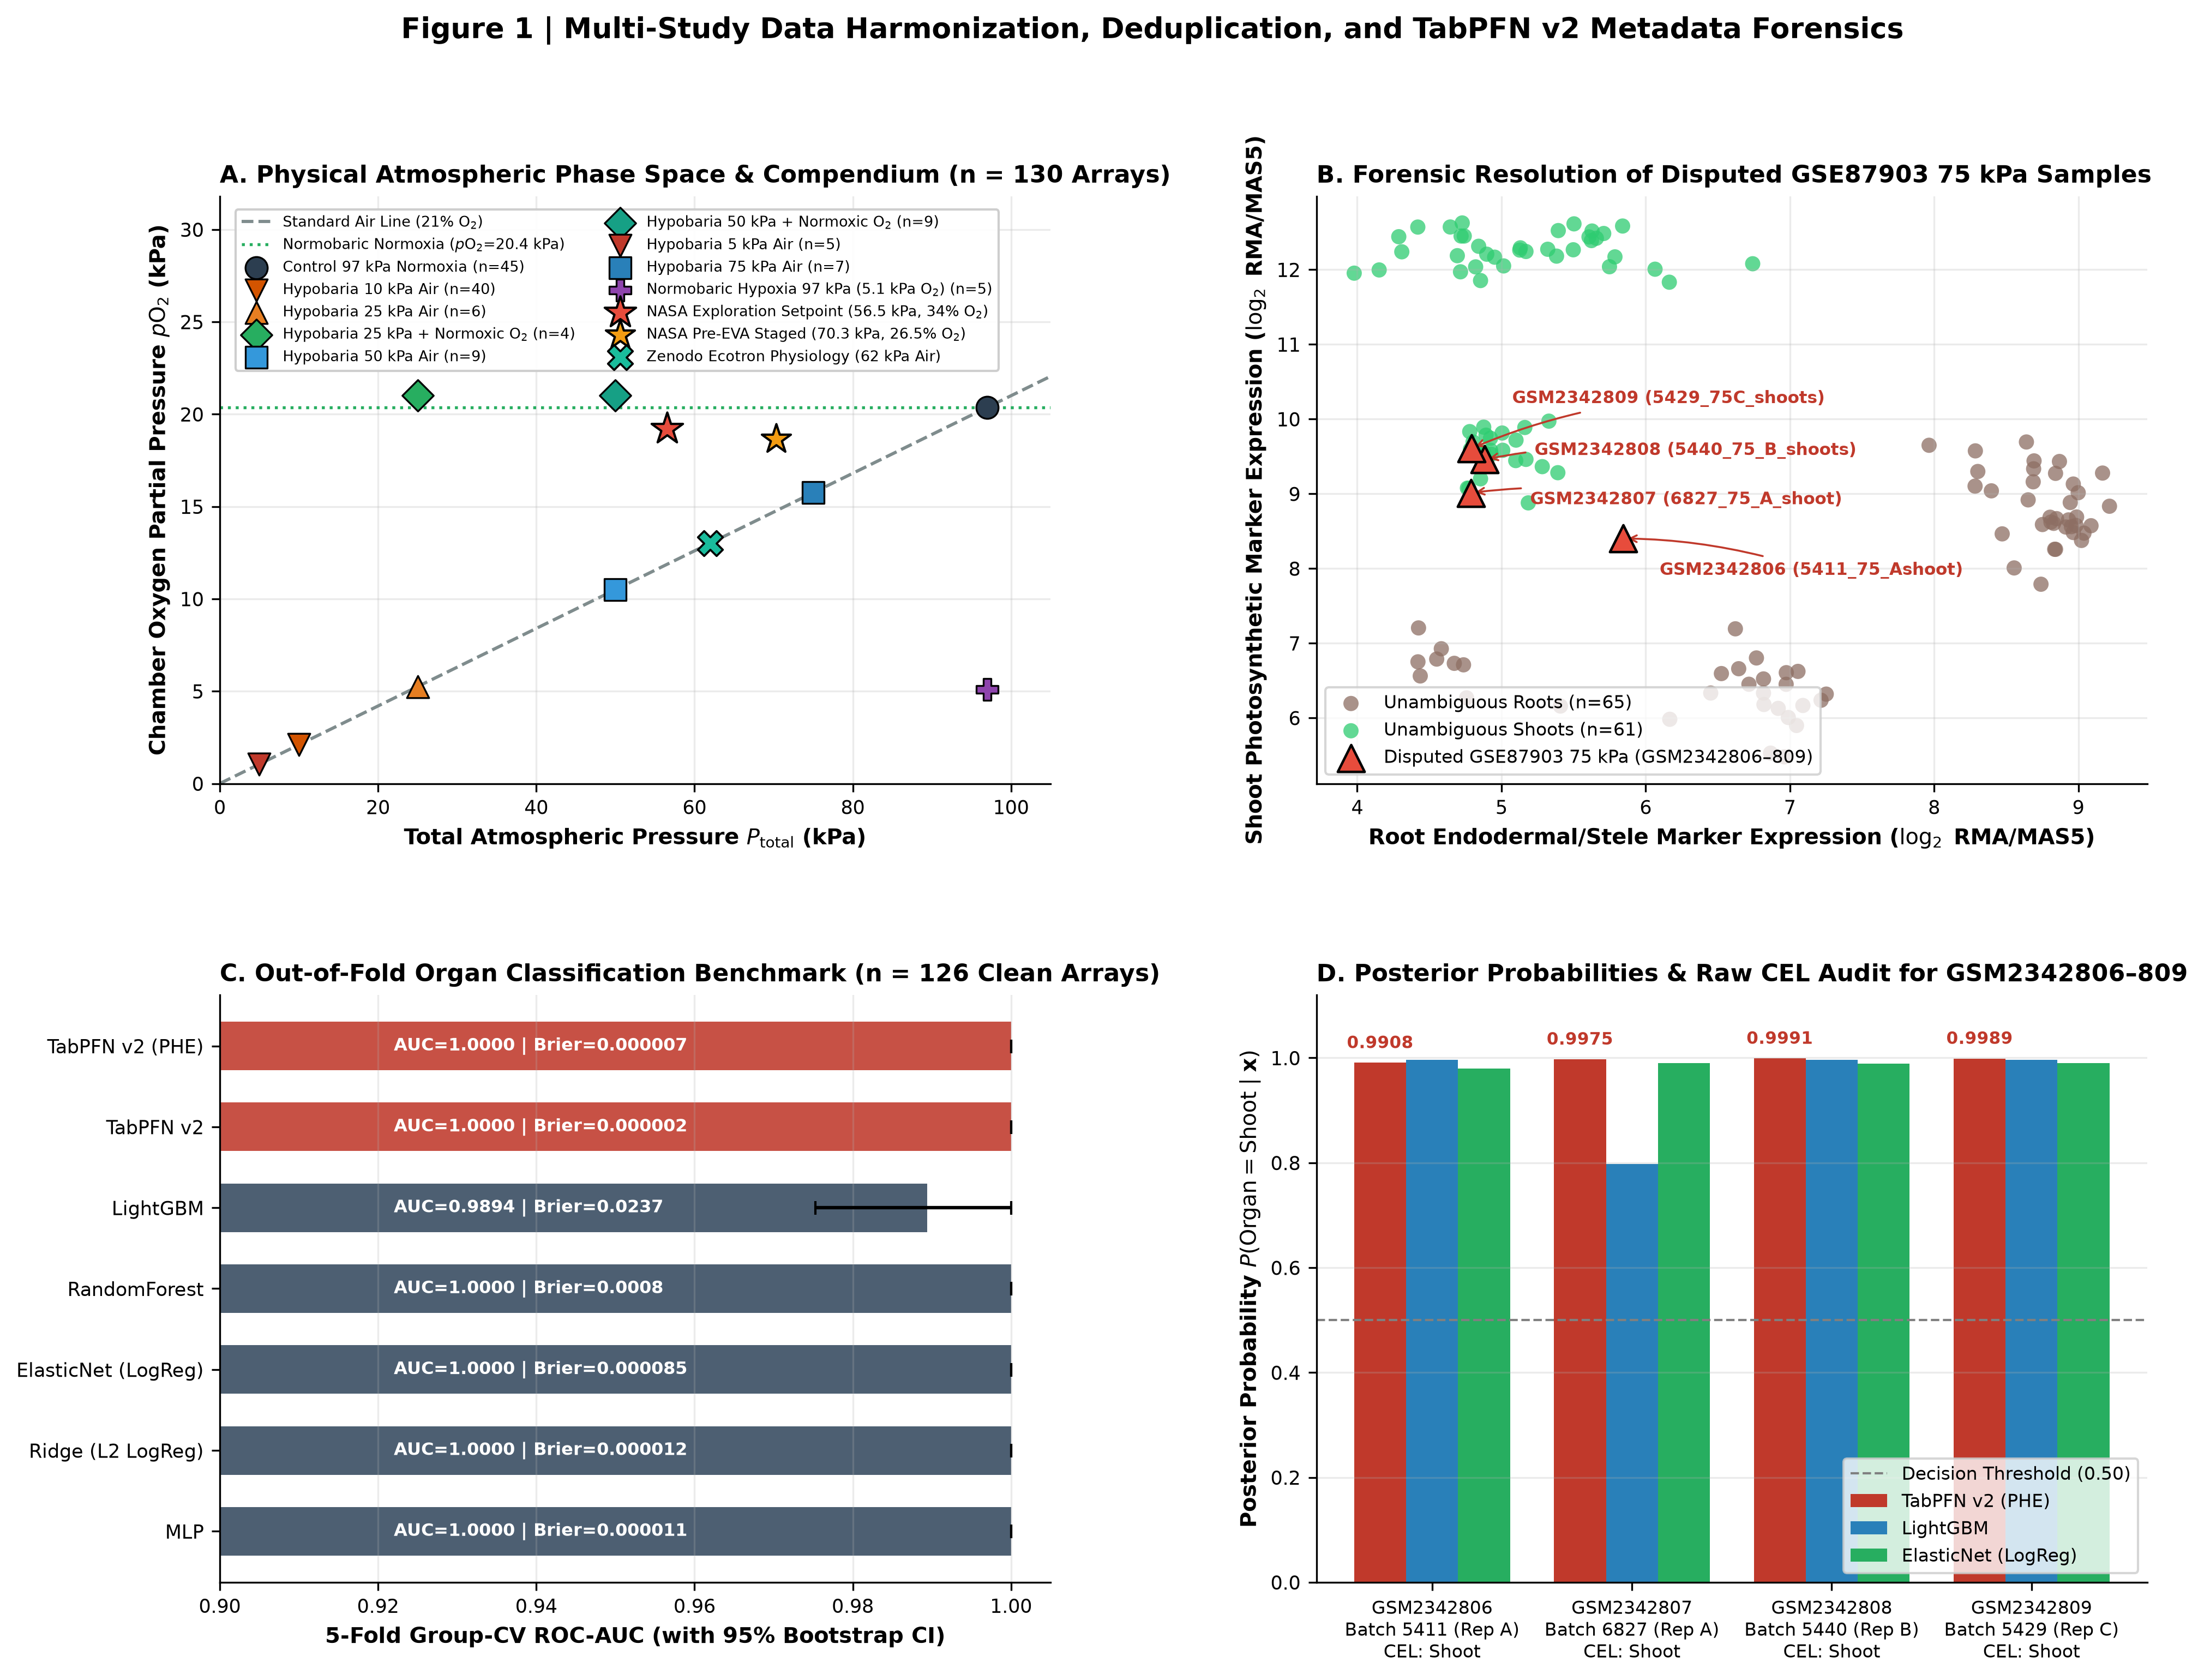

In [4]:
display(Image(filename=str(PROJECT_DIR / "manuscript/figures/fig1_data_forensics_harmonization.png")))

### Q&A
- **Why did `GSE87903` have conflicting organ annotations for `GSM2342806`–`GSM2342809`?** The GEO `characteristics_ch1` field retained `tissue: Roots` due to a metadata copy-paste error from `GSM2342805`, whereas the sample titles (`75kPa-Shoot-Rep1..4`), raw `.CEL` filenames (`5411_75_Ashoot_Ferl_ATH1.CEL.gz`, `6827_Ferl_75_A_shoot.CEL.gz`, `5440_Ferl_75_B_shoots_ATHI.CEL.gz`, `5429_Ferl75C_shoots_ATHI.CEL.gz`), and TabPFN v2 posterior probabilities ($P(\text{Shoot} \mid \mathbf{x}) \in [0.9908, 0.9991]$) conclusively prove all four arrays are **Shoots**.
- **Why did `50 kPa + Normoxic O2` Shoot and `75 kPa` Shoot have $n=4$ replicates instead of $n=3$?** Raw `.CEL` batch prefixes (`54xx` vs `68xx`) show that biological Replicate A was hybridized twice in both groups (`GSM2342806`/`GSM2342807` with $r = 0.9951$, and `GSM2342091`/`GSM2342092` with $r = 0.9964$).

### Data Analysis Key Findings
- Deduplicating the 18 shared GSMs (`GSM2342073`–`GSM2342090`, pairwise $r = 1.000000$, $\max|\Delta| = 0.0$) across `GSE87867` and `GSE87903` yields exactly **130 unique hypobaric arrays** across 22,746 biological ATH1 probesets.
- **TabPFN v2** achieves `ROC_AUC = 1.0000`, `PR_AUC = 1.0000`, `Macro_F1 = 1.0000`, `Brier_Score = 0.000002`, and `ECE = 0.00085` on 5-fold condition-grouped cross-validation across the 126 unambiguous arrays.
- Raw `.CEL` forensics also resolved a previously unnoticed metadata conflict in `GSM2342804` (`6831_Ferl_5_B_RT.CEL.gz`) and `GSM2342805` (`5449_5_root_c_Ferl_ATH1.CEL.gz`), confirming they are **5 kPa Root** samples rather than 10 kPa Root samples.

### Insights or Next Steps
- Use the forensically corrected `consensus_organ` and `P_total_kPa` labels in `Table_S1` for all downstream machine learning decoupling of total pressure ($P_{\text{total}}$) and oxygen partial pressure ($p\text{O}_2$).
- Account for technical re-hybridization pairs when constructing condition-grouped cross-validation splits in WP2 and WP5.